# SARIMAX Model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

## Import Data

In [2]:
df = pd.read_parquet(r"../Data/cleaned_data/all.parquet")
df.head()

,interval_start_utc,interval_end_utc,publish_time_utc_rtm,load_forecast,lmp_rtm,energy_rtm,congestion_rtm,loss_rtm,publish_time_utc_dam,north_wind,...,south_wind,miso_wind,north_solar,central_solar,south_solar,miso_solar,lmp_dam,energy_dam,congestion_dam,loss_dam
0,2023-03-25 01:55:00+00:00,2023-03-25 02:00:00+00:00,2023-03-24 05:00:00+00:00,71099,28.03,22.55,5.17,0.31,2023-03-23 20:15:12+00:00,5416.1,...,0.0,9920.8,3.9,1.0,1.2,6.1,26.92,26.09,1.66,-0.83
1,2023-03-25 02:00:00+00:00,2023-03-25 02:05:00+00:00,2023-03-24 05:00:00+00:00,70934,25.08,21.13,3.70,0.25,2023-03-23 20:15:12+00:00,6123.7,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
2,2023-03-25 02:05:00+00:00,2023-03-25 02:10:00+00:00,2023-03-24 05:00:00+00:00,70768,27.07,23.40,3.46,0.21,2023-03-23 20:15:12+00:00,6123.7,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
3,2023-03-25 02:10:00+00:00,2023-03-25 02:15:00+00:00,2023-03-24 05:00:00+00:00,70602,26.10,22.67,3.21,0.22,2023-03-23 20:15:12+00:00,6123.7,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85
4,2023-03-25 02:15:00+00:00,2023-03-25 02:20:00+00:00,2023-03-24 05:00:00+00:00,70436,24.82,23.07,1.57,0.18,2023-03-23 20:15:12+00:00,6123.7,...,0.0,10810.9,0.0,0.0,0.0,0.0,23.70,23.31,2.24,-1.85


## Configuration

In [3]:
DATE_COL = "interval_start_utc"
TARGET_COL = "lmp_rtm"

# Train / Validation / Test Cutoffs
TRAIN_END_DATE = "2025-07-01 00:00:00+00:00"
VAL_END_DATE   = "2026-07-01 00:00:00+00:00"

# Horizon and Windowing
FORECAST_HORIZON = 288       # 288 steps = 24 hours (at 5-min resolution)
STRIDE_STEPS     = 300       # Step size for rolling validation (48 steps = 6 hours) (300 steps = 25 hours (no overlap for efficiency))
LOOKBACK_STEPS   = 2016      # Historical context window for training/refitting (2016 steps = 7 days)

# Model Hyperparameters
FOURIER_K        = 4         # Number of Fourier pairs for daily cycle (288 steps/day)
ARIMA_ORDER      = (1, 0, 1) # Simple low-order residual ARIMA structure (p, d, q)

# Exogenous features to include alongside Fourier terms
EXOG_COLS = ["lmp_dam", "load_forecast"]

## Preprocessing

Cleans time series, handles missing values, sets index, and sorts.

In [4]:
def preprocess_and_clean_data(df: pd.DataFrame) -> pd.DataFrame:
    """
    Cleans time series, handles missing values, sets datetime index,
    and sorts chronologically.
    """
    data = df.copy()
    
    # 1. Datetime formatting and index setup
    data[DATE_COL] = pd.to_datetime(data[DATE_COL])
    data = data.sort_values(DATE_COL).reset_index(drop=True)
    data = data.set_index(DATE_COL)
    
    # 2. Linear Interpolation for missing target values
    if data[TARGET_COL].isnull().sum() > 0:
        print(f"Interpolating {data[TARGET_COL].isnull().sum()} missing values in {TARGET_COL}...")
        data[TARGET_COL] = data[TARGET_COL].interpolate(method='time').bfill().ffill()
        
    # 3. Interpolate missing values in exogenous features if present
    for col in EXOG_COLS:
        if data[col].isnull().sum() > 0:
            data[col] = data[col].interpolate(method='time').bfill().ffill()

    # 4. Set all values over 1000 to 1000
    data[TARGET_COL] = data[TARGET_COL].clip(upper=1000)
            
    return data

In [5]:
df_clean = preprocess_and_clean_data(df)

Interpolating 5602 missing values in lmp_rtm...


## Log Transformaiton 

In [6]:
def apply_shifted_log_transform(df: pd.DataFrame, target_col: str):
    """
    Applies y_t = log(LMP + C) where C = |min(LMP)| + 1 to safely convert
    negative and zero prices into log domain without destroying order or rank.
    """
    min_val = df[target_col].min()
    shift_constant = abs(min_val) + 1.0 if min_val <= 0 else 0.0
    
    df['target_transformed'] = np.log(df[target_col] + shift_constant)
    return df, shift_constant

def plot_transformation_diagnostics(df: pd.DataFrame, orig_col: str, trans_col: str):
    """
    Generates comparative visualizations showing how shifted log transform
    compresses extreme price spikes into a near-normal distribution.
    """
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    
    # Original LMP Time Series
    axes[0, 0].plot(df.index[:288*7], df[orig_col].iloc[:288*7], color='crimson')
    axes[0, 0].set_title("Raw LMP Series (7-Day Sample)")
    axes[0, 0].set_ylabel("$/MWh")
    
    # Transformed LMP Time Series
    axes[0, 1].plot(df.index[:288*7], df[trans_col].iloc[:288*7], color='navy')
    axes[0, 1].set_title("Shifted Log Transformed Series (7-Day Sample)")
    axes[0, 1].set_ylabel("Log Scale")
    
    # Distribution - Raw
    sns.histplot(df[orig_col], bins=100, ax=axes[1, 0], kde=True, color='crimson')
    axes[1, 0].set_title("Raw LMP Distribution (Heavy Spike Tails)")
    axes[1, 0].set_yscale('log')
    
    # Distribution - Transformed
    sns.histplot(df[trans_col], bins=100, ax=axes[1, 1], kde=True, color='navy')
    axes[1, 1].set_title("Transformed LMP Distribution (Stabilized Variance)")
    
    plt.tight_layout()
    plt.show()

# Inverse Transformation Helper
def inverse_shifted_log(transformed_vals, shift_constant):
    """Converts log-scale predictions back to real $/MWh values."""
    return np.exp(transformed_vals) - shift_constant

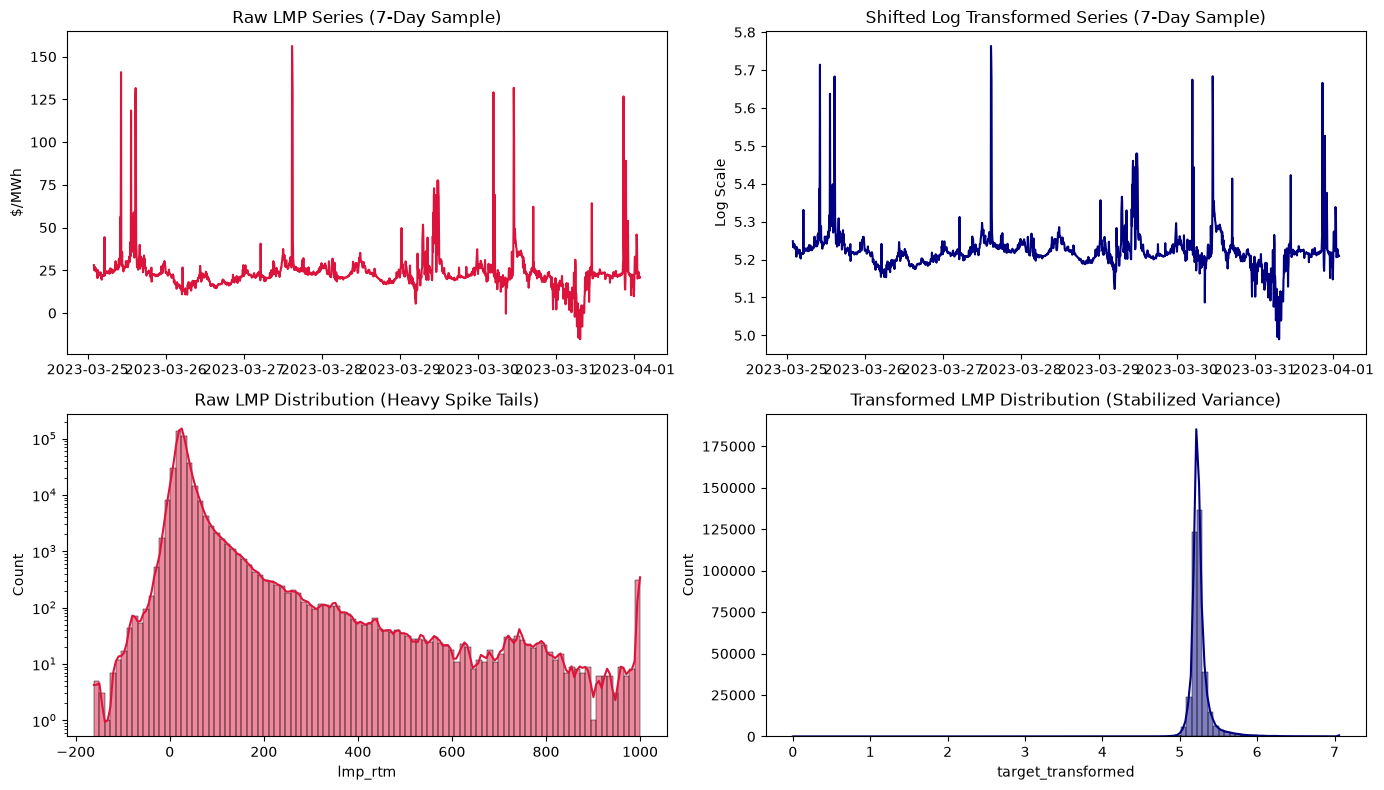

In [7]:
df_clean, shift_const = apply_shifted_log_transform(df_clean, TARGET_COL)
plot_transformation_diagnostics(df_clean, TARGET_COL, 'target_transformed')

## Fourier Feature Generation

In [8]:
def generate_fourier_terms(df: pd.DataFrame, period: float = 288.0, k_terms: int = 4) -> pd.DataFrame:
    """
    Generates k Sine and Cosine harmonic pairs for a daily 288-step cycle.
    """
    fourier_df = pd.DataFrame(index=df.index)
    
    # Integer time index for continuous sine/cosine evaluation
    t = np.arange(len(df))
    
    for k in range(1, k_terms + 1):
        fourier_df[f'sin_{k}'] = np.sin(2 * np.pi * k * t / period)
        fourier_df[f'cos_{k}'] = np.cos(2 * np.pi * k * t / period)
        
    return fourier_df

def construct_exogenous_matrix(df: pd.DataFrame, fourier_df: pd.DataFrame, exog_cols: list) -> pd.DataFrame:
    """Combines Fourier terms with external market features into a unified matrix X."""
    X = pd.concat([fourier_df, df[exog_cols]], axis=1)
    return X

In [9]:
fourier_df = generate_fourier_terms(df_clean, period=288, k_terms=FOURIER_K)
X_matrix = construct_exogenous_matrix(df_clean, fourier_df, EXOG_COLS)

## Validation Pipeline

In [10]:
def run_rolling_sarimax_validation(
    df: pd.DataFrame,
    X_matrix: pd.DataFrame,
    trans_target_col: str,
    orig_target_col: str,
    shift_constant: float,
    train_end: str,
    val_end: str,
    horizon: int = 288,
    stride: int = 48,
    lookback: int = 2016,
    order: tuple = (1, 0, 1)
):
    """
    Executes a rolling-window 288-step dynamic forecast evaluation across
    the validation set using SARIMAX + Fourier exogenous inputs.
    """
    # Split index boundaries
    val_mask = (df.index >= train_end) & (df.index < val_end)
    val_indices = np.where(val_mask)[0]
    
    # Ensure validation sequence has room for full horizon evaluation
    valid_start_indices = [idx for idx in val_indices[::stride] if idx + horizon <= len(df)]
    
    forecasts_real = []
    actuals_real = []
    forecast_timestamps = []
    
    print(f"Beginning Rolling Validation across {len(valid_start_indices)} origins...")
    
    for i, t_origin in enumerate(valid_start_indices):
        # Define historical training window
        t_start = max(0, t_origin - lookback)
        
        # Extract target slices
        y_train = df[trans_target_col].iloc[t_start:t_origin]
        
        # Extract exogenous matrix slices (Train vs. Horizon Future)
        X_train = X_matrix.iloc[t_start:t_origin]
        X_forecast = X_matrix.iloc[t_origin : t_origin + horizon]
        
        # Fit SARIMAX on residual errors after Fourier + Exog fit
        model = SARIMAX(
            endog=y_train,
            exog=X_train,
            order=order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        fitted_model = model.fit(disp=False)
        
        # Generate 288-step vector prediction in log space
        log_pred = fitted_model.forecast(steps=horizon, exog=X_forecast)
        
        # Inverse transform back to $/MWh
        real_pred = inverse_shifted_log(log_pred.values, shift_constant)
        real_actual = df[orig_target_col].iloc[t_origin : t_origin + horizon].values
        
        # Append outputs
        forecasts_real.append(real_pred)
        actuals_real.append(real_actual)
        forecast_timestamps.append(df.index[t_origin : t_origin + horizon])
        
        if (i + 1) % 50 == 0 or (i + 1) == len(valid_start_indices):
            print(f"Completed {i + 1}/{len(valid_start_indices)} rolling origins.")
            
    return np.array(forecasts_real), np.array(actuals_real), forecast_timestamps

In [11]:
forecasts, actuals, timestamps = run_rolling_sarimax_validation(
    df=df_clean,
    X_matrix=X_matrix,
    trans_target_col='target_transformed',
    orig_target_col=TARGET_COL,
    shift_constant=shift_const,
    train_end=TRAIN_END_DATE,
    val_end=VAL_END_DATE,
    horizon=FORECAST_HORIZON,
    stride=STRIDE_STEPS,
    lookback=LOOKBACK_STEPS,
    order=ARIMA_ORDER
)

Beginning Rolling Validation across 351 origins...


c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency 5min will be used.
  self._init_dates(dates, freq)
c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency 5min will be used.
  self._init_dates(dates, freq)
c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency 5min will be used.
  self._init_dates(dates, freq)

Completed 50/351 rolling origins.


c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency 5min will be used.
  self._init_dates(dates, freq)
c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency 5min will be used.
  self._init_dates(dates, freq)
c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Use

Completed 100/351 rolling origins.


...

Completed 250/351 rolling origins.


c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency 5min will be used.
  self._init_dates(dates, freq)
c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency 5min will be used.
  self._init_dates(dates, freq)
c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Use

Completed 300/351 rolling origins.


c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency 5min will be used.
  self._init_dates(dates, freq)
c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency 5min will be used.
  self._init_dates(dates, freq)
c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\krawz\Courses\Fall2026\capstone\data-science-capstone\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency 5min will be used.
  self._init_dates(dates, freq)

Completed 350/351 rolling origins.
Completed 351/351 rolling origins.


## Performance Metrics

In [12]:
def evaluate_forecast_performance(forecasts: np.ndarray, actuals: np.ndarray):
    """
    Computes summary performance metrics both overall and by forecast horizon step.
    """
    # Overall Metrics across all rolling windows and horizon steps
    mae_overall = mean_absolute_error(actuals.flatten(), forecasts.flatten())
    rmse_overall = np.sqrt(mean_squared_error(actuals.flatten(), forecasts.flatten()))
    
    print("=" * 45)
    print("      OVERALL VALIDATION PERFORMANCE")
    print("=" * 45)
    print(f"Overall MAE  : ${mae_overall:.2f} /MWh")
    print(f"Overall RMSE : ${rmse_overall:.2f} /MWh")
    print("=" * 45)
    
    # Horizon Breakdown (Performance at 15m, 1h, 6h, 12h, 24h)
    horizon_steps = [3, 12, 72, 144, 288] # 1-indexed steps
    step_labels   = ["15 mins", "1 hour", "6 hours", "12 hours", "24 hours"]
    
    print("\n" + "=" * 45)
    print("   PERFORMANCE BY FORECAST HORIZON STEP")
    print("=" * 45)
    for step_idx, label in zip(horizon_steps, step_labels):
        h_idx = step_idx - 1 # convert to zero-indexed
        mae_step = mean_absolute_error(actuals[:, h_idx], forecasts[:, h_idx])
        rmse_step = np.sqrt(mean_squared_error(actuals[:, h_idx], forecasts[:, h_idx]))
        print(f"Horizon t+{step_idx:03d} ({label:8s}) -> MAE: ${mae_step:6.2f} | RMSE: ${rmse_step:6.2f}")
        
    return mae_overall, rmse_overall

In [13]:
mae, rmse = evaluate_forecast_performance(forecasts, actuals)

      OVERALL VALIDATION PERFORMANCE
Overall MAE  : $53.69 /MWh
Overall RMSE : $94.00 /MWh

   PERFORMANCE BY FORECAST HORIZON STEP
Horizon t+003 (15 mins ) -> MAE: $ 13.72 | RMSE: $ 23.99
Horizon t+012 (1 hour  ) -> MAE: $ 21.95 | RMSE: $ 31.43
Horizon t+072 (6 hours ) -> MAE: $ 49.68 | RMSE: $ 80.43
Horizon t+144 (12 hours) -> MAE: $ 54.15 | RMSE: $ 92.94
Horizon t+288 (24 hours) -> MAE: $ 64.96 | RMSE: $122.42


## Visualizing Performance

In [14]:
def plot_random_forecast_intervals(
    forecasts: np.ndarray,
    actuals: np.ndarray,
    timestamps: list,
    n_samples: int = 4,
    random_seed: int = 42
):
    """
    Randomly selects 'n_samples' rolling forecast origin windows and plots
    the predicted vs. actual LMP values over the 288-step (24-hour) horizon.
    
    Parameters:
    -----------
    forecasts   : np.ndarray of shape (N_origins, 288)
    actuals     : np.ndarray of shape (N_origins, 288)
    timestamps  : list of DatetimeIndexes, each length 288
    n_samples   : Number of random forecast intervals to display
    random_seed : Seed for reproducible random sampling
    """
    np.random.seed(random_seed)
    total_windows = len(forecasts)
    
    # Ensure n_samples does not exceed available windows
    n_samples = min(n_samples, total_windows)
    selected_indices = np.random.choice(total_windows, size=n_samples, replace=False)
    
    # Determine grid layout (e.g., 2 columns)
    cols = 2 if n_samples > 1 else 1
    rows = (n_samples + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows), sharey=False)
    
    # Flatten axes array for easy indexing if multi-row/col
    if n_samples == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
        
    for i, idx in enumerate(selected_indices):
        ax = axes[i]
        
        time_axis = timestamps[idx]
        y_true = actuals[idx]
        y_pred = forecasts[idx]
        
        # Plot Actual vs. Predicted
        ax.plot(time_axis, y_true, label='Actual LMP', color='black', alpha=0.8, linewidth=1.5)
        ax.plot(time_axis, y_pred, label='SARIMAX Forecast', color='crimson', linestyle='--', linewidth=1.5)
        
        # Formatting individual subplot
        start_time_str = time_axis[0].strftime('%Y-%m-%d %H:%M UTC')
        ax.set_title(f"Forecast Origin $t=0$: {start_time_str}", fontsize=11, fontweight='bold')
        ax.set_ylabel("LMP ($/MWh)", fontsize=10)
        ax.set_xlabel("Time (UTC)", fontsize=10)
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(loc='upper left', frameon=True)
        
        # Rotate x-axis labels for readability
        ax.tick_params(axis='x', rotation=30)

    # Hide any unused subplot axes
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    plt.suptitle("Rolling 24-Hour Horizon Forecasts vs. Actuals (Random Samples)", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

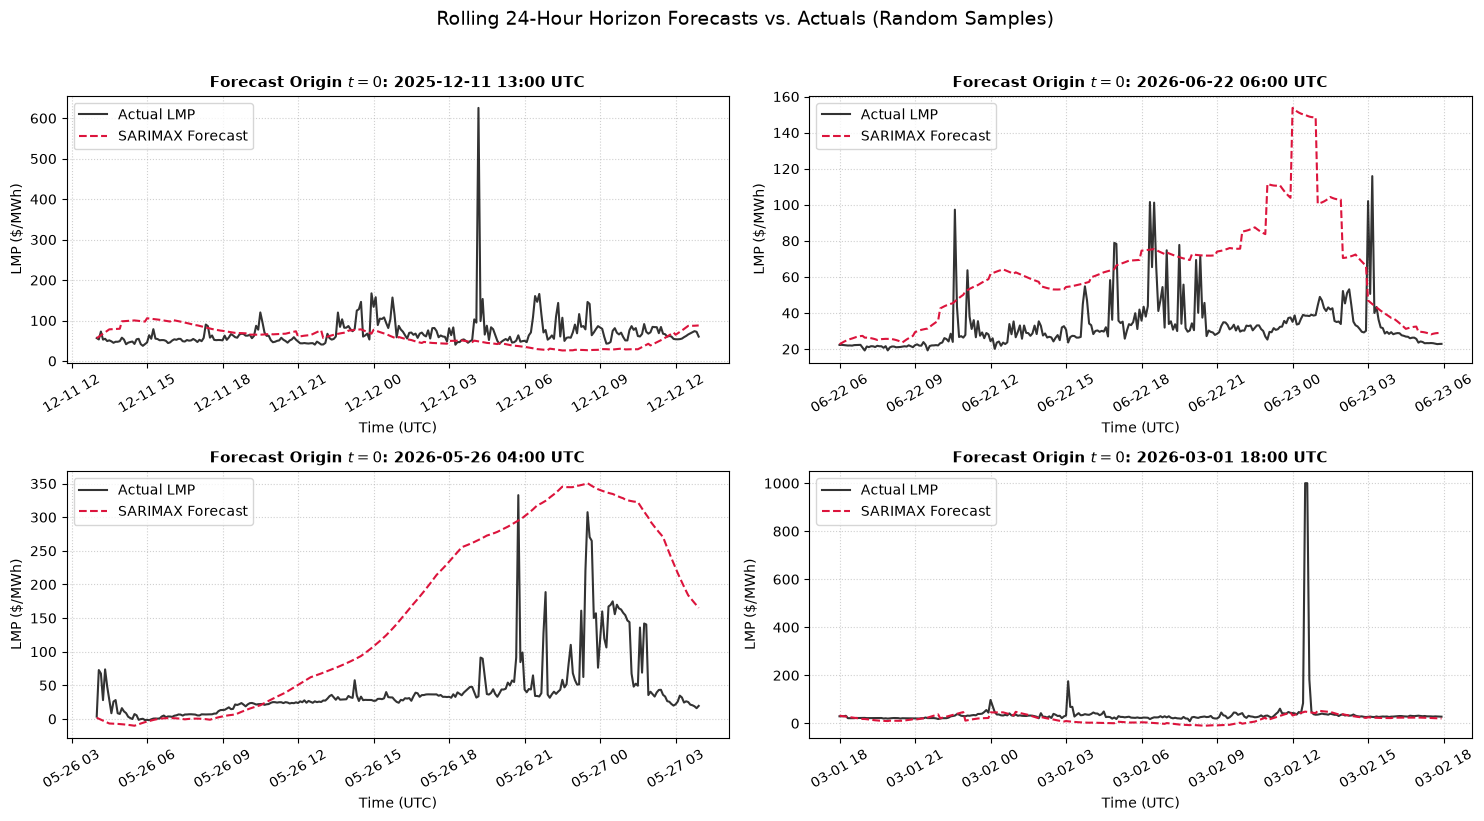

In [15]:

plot_random_forecast_intervals(
    forecasts=forecasts,
    actuals=actuals,
    timestamps=timestamps,
    n_samples=4,      # Number of random windows to inspect
    random_seed=42    # Change seed to sample different intervals
)

## Questions I have

- Is this an appropreate way to handel outliers?
- Is there any way to make the evaluation faster so it is realistic to tune hyperparameters with overlap?